# Bench 1 (strategy in time)

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, ScalarFormatter

def plot_time_by_strategy(csv_path: str, log_scale: bool = True, export_path: str = None):
    """
    Reads the CSV from the first table and plots execution Time (s)
    vs number of threads (T), with a line for each strategy.

    Parameters
    ----------
    csv_path : str
        Path to the CSV file containing the table.
    log_scale : bool
        If True, use logarithmic scale for the y-axis.
    """
    # Load data
    df = pd.read_csv(csv_path)

    # Ensure numeric types
    df["T"] = pd.to_numeric(df["T"], errors="coerce")
    df["Time (s)"] = pd.to_numeric(df["Time (s)"], errors="coerce")

    # Plot
    plt.figure(figsize=(10, 6))
    for strat, group in df.groupby("Strat"):
        plt.plot(group["T"], group["Time (s)"], marker="o", label=strat)

    plt.xlabel("Threads (T)")
    plt.ylabel("Time log(s)")
    plt.title("Execution Time per Strategy vs Threads")

    if log_scale:
        plt.yscale("log")
        # Major ticks: powers of 10, formatted as plain integers
        plt.gca().yaxis.set_major_locator(LogLocator(base=10.0, subs=[1]))
        plt.gca().yaxis.set_major_formatter(ScalarFormatter())
        plt.gca().yaxis.set_minor_formatter(ScalarFormatter())  # optional

    plt.legend(title="Strategy")
    plt.grid(True, which="both", linestyle="--", alpha=0.6)
    plt.tight_layout()
    if export_path:
        plt.savefig(export_path, dpi=300, bbox_inches="tight")
    plt.show()

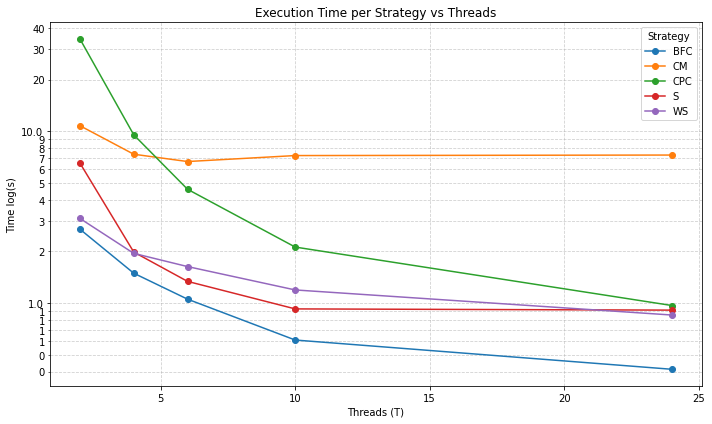

In [83]:
plot_time_by_strategy("data/chr22.bench.1.csv", True, "data/chr22.bench.1.png")

# Bench 2

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, ScalarFormatter

def plot_time_for_chromosome(csv_path: str, chromosome: str, log_scale: bool = True, save_path: str = None):
    """
    Reads the CSV from the second table and plots execution Time (s)
    vs number of threads (T) for a given chromosome.
    Colors correspond to Flag, line style corresponds to Tool (SV=solid, BV=dotted).
    
    Parameters
    ----------
    csv_path : str
        Path to the CSV file containing the table.
    chromosome : str
        Chromosome to plot (e.g., "chr22" or "chr1").
    log_scale : bool
        If True, use logarithmic scale for the y-axis.
    save_path : str, optional
        If provided, save the plot to this file (e.g., 'chr22_plot.png').
    """
    # Load data
    df = pd.read_csv(csv_path)

    # Ensure numeric types
    df["T"] = pd.to_numeric(df["T"], errors="coerce")
    df["Time (s)"] = pd.to_numeric(df["Time (s)"], errors="coerce")

    # Filter chromosome
    sub_df = df[df["File"] == chromosome]
    if sub_df.empty:
        raise ValueError(f"No data found for {chromosome}")

    # Assign consistent colors per flag
    flags = sub_df["Flag"].unique()
    color_map = {flag: color for flag, color in zip(flags, plt.cm.tab10.colors)}

    # Line style per tool
    tool_styles = {"SV": ":", "BV": "-"}

    # Plot
    plt.figure(figsize=(8, 6))
    for (flag, tool), group in sub_df.groupby(["Flag", "Tool"]):
        group = group.sort_values("T")
        label = f"{flag}-{tool}"
        plt.plot(
            group["T"], group["Time (s)"],
            marker="o",
            color=color_map[flag],
            linestyle=tool_styles.get(tool, "-"),
            label=label
        )

    plt.xlabel("Threads (T)")
    plt.ylabel("Time (log(s))")
    plt.title(f"Execution Time vs Threads — {chromosome}")

    if log_scale:
        plt.yscale("log")
        ax = plt.gca()
        ax.yaxis.set_major_locator(LogLocator(base=10.0, subs=[1.0]))
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=[2, 3, 5], numticks=10))
        ax.yaxis.set_minor_formatter(plt.NullFormatter())

    plt.grid(True, which="both", linestyle="--", alpha=0.6)

    # After plotting all series, collect handles and labels
    handles, labels = plt.gca().get_legend_handles_labels()

    # Define desired order and mapping
    order = ["0x4-SV", "0x4-BV", "0x10-SV", "0x10-BV", "0x2-SV", "0x2-BV"]
    label_map = {
        "0x2-SV": "Flag 0x2 — samtools",
        "0x2-BV": "Flag 0x2 — bafiq",
        "0x4-SV": "Flag 0x4 — samtools",
        "0x4-BV": "Flag 0x4 — bafiq",
        "0x10-SV": "Flag 0x10 — samtools",
        "0x10-BV": "Flag 0x10 — bafiq",
    }

    # Reorder handles and labels
    handles_ordered = [handles[labels.index(k)] for k in order if k in labels]
    labels_ordered = [label_map[k] for k in order if k in labels]

    # Place legend outside
    plt.legend(handles_ordered, labels_ordered,
            title="Flag / Tool",
            bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # leave space for legend

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

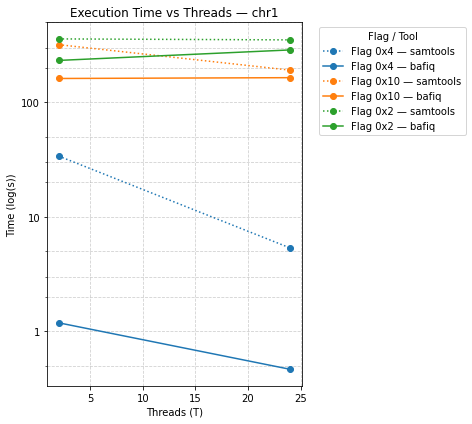

In [80]:
plot_time_for_chromosome("data/chr1.chr22.bench.2.csv", "chr1", log_scale=True, save_path="data/chr1.bench.2.png")

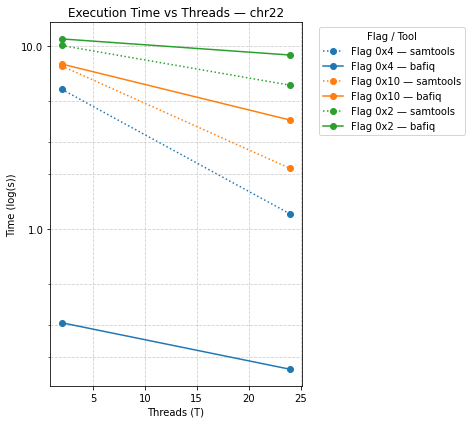

In [81]:
plot_time_for_chromosome("data/chr1.chr22.bench.2.csv", "chr22", log_scale=True, save_path="data/chr22.bench.2.png")